# Simple logistic classifier

Using the color of each pixel in the image to classify if that pixel is floor or not. 

Being a pixel by pixel classifier the datasets will be datasets of pixels and not of images.

In [1]:
import matplotlib.pyplot as plt

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, binary_target_mask, make_data_splits, build_pixel_dataset,evaluate

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

N_PIXELS = 100

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

X_train, y_train = build_pixel_dataset(nyu, train_indices, target_ids, N_PIXELS, RANDOM_STATE)
X_test, y_test = build_pixel_dataset(nyu, test_indices, target_ids, N_PIXELS, RANDOM_STATE)

Train images: 1028
Validation images: 206
Test images: 215


AUC:      0.625
AP:       0.160
Accuracy: 0.562  (baseline 'always not floor': 0.885)
IoU:      0.147
              precision    recall  f1-score   support

   not floor       0.93      0.55      0.69     19035
       floor       0.16      0.66      0.26      2465

    accuracy                           0.56     21500
   macro avg       0.54      0.60      0.47     21500
weighted avg       0.84      0.56      0.64     21500



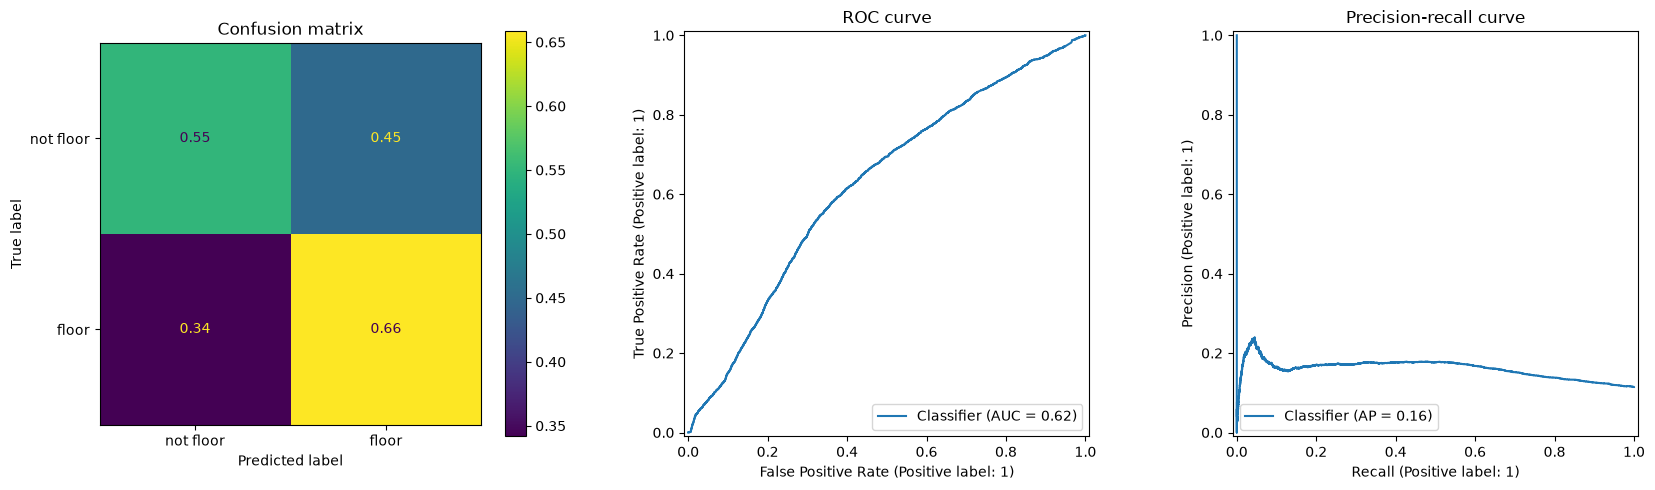

In [4]:
clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(X_train, y_train)

y_proba = clf.predict_proba(X_test)[:, 1]
evaluate(y_test, y_proba)

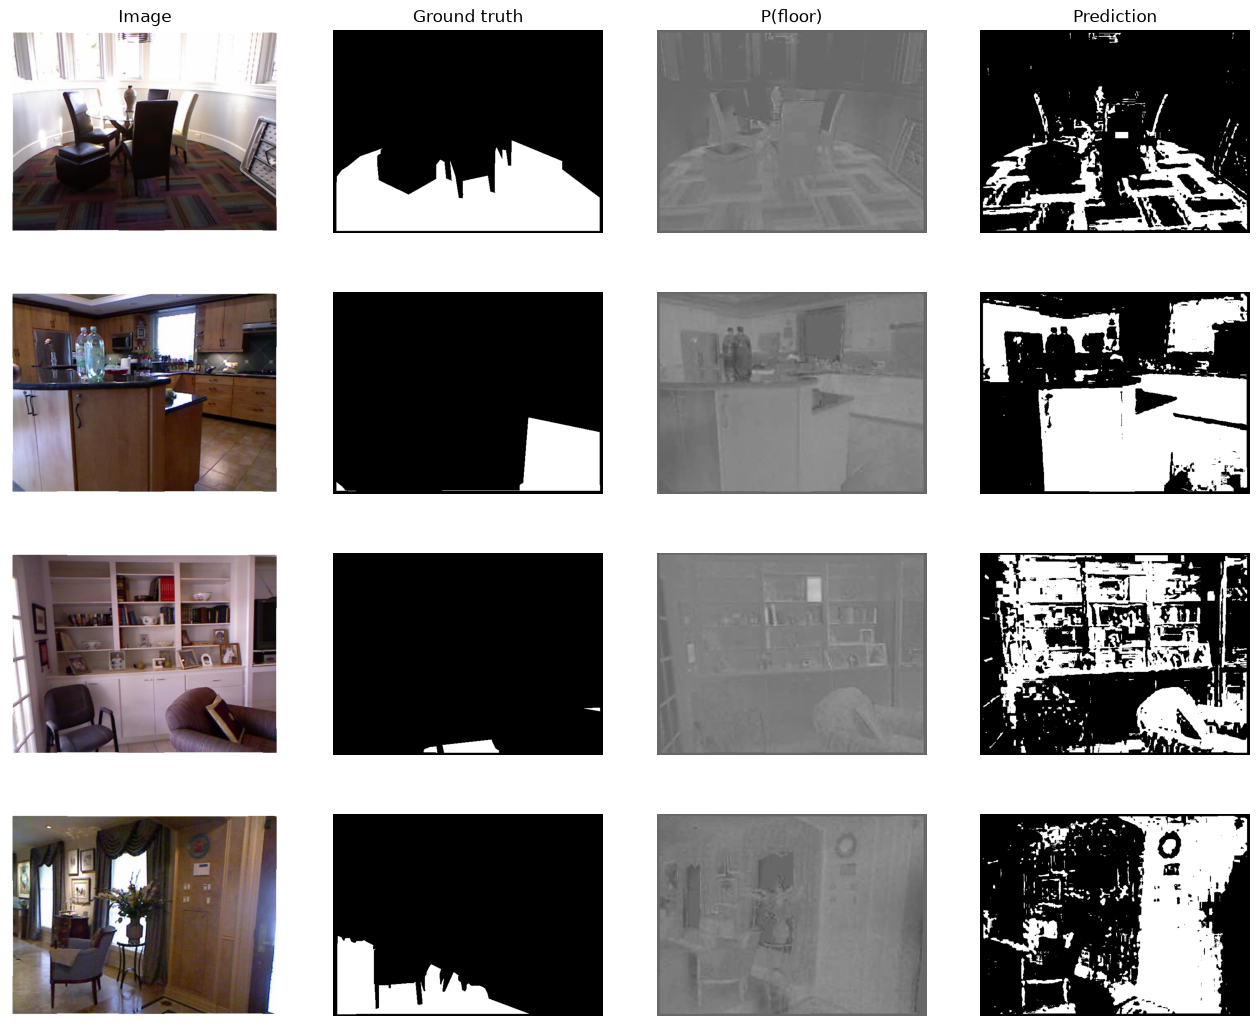

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)

    # Ground truth: 1 = floor, 0 = everything else
    gt = binary_target_mask(labels, target_ids)

    # Predict P(floor) for every pixel, then reshape back to image size
    X = image.reshape(-1, 3) / 255.0
    proba = clf.predict_proba(X)[:, 1].reshape(labels.shape)

    # Final prediction
    pred = clf.predict(X).reshape(labels.shape)

    axes[row, 0].imshow(image)
    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()